In [1]:
import numpy as np
import matplotlib.pyplot as plt

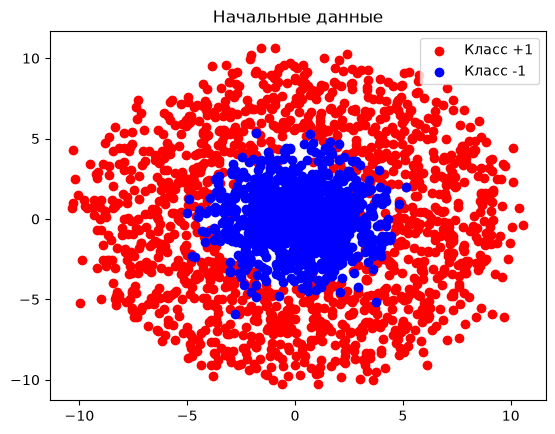

In [2]:
n_samples = 1488*67//42

r = np.random.uniform(0, 10, n_samples)
theta = np.random.uniform(0, 2 * np.pi, n_samples)
X = np.c_[r * np.cos(theta), r * np.sin(theta)]

y = np.where(r > 4.2, 1, -1)

X += np.random.normal(0, 0.67, X.shape)

plt.scatter(X[y==1, 0], X[y==1, 1], color='red', label='Класс +1')
plt.scatter(X[y==-1, 0], X[y==-1, 1], color='blue', label='Класс -1')
plt.legend()
plt.title("Начальные данные")
plt.show()

In [3]:
def expand_features(matrix):
    x1 = matrix[:, [0]]
    x2 = matrix[:, [1]]
    ones = np.ones((matrix.shape[0], 1))
    
    return np.c_[x1, x2, x1**2, x2**2, ones]
    
new_matrix = expand_features(X)

In [4]:
w = np.linalg.inv(new_matrix.T @ new_matrix) @ (new_matrix.T @ y)
w

array([-6.14437291e-03,  6.17651673e-05,  2.48952905e-02,  2.50575179e-02,
       -7.15385904e-01])

In [5]:
def predict(new_matrix, w):
    return np.sign(new_matrix @ w)

In [6]:
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

In [7]:
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))

In [8]:
X_grid = np.c_[xx.ravel(), yy.ravel()]

In [9]:
grid_expanded = expand_features(X_grid)
Z = predict(grid_expanded, w)
Z = Z.reshape(xx.shape)

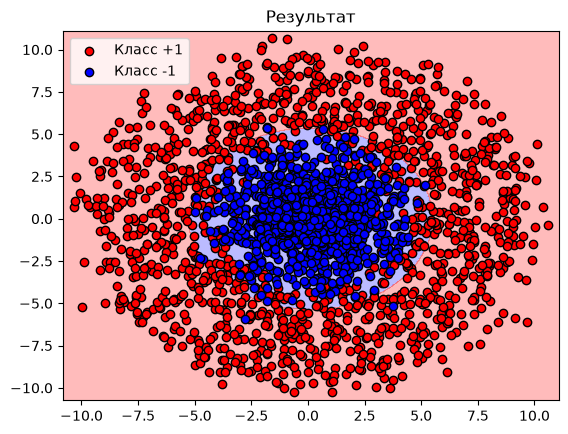

In [10]:
plt.contourf(xx, yy, Z, alpha=0.3, cmap='bwr')
plt.scatter(X[y==1, 0], X[y==1, 1], color='red',edgecolor='k', label='Класс +1')
plt.scatter(X[y==-1, 0], X[y==-1, 1], color='blue',edgecolor='k', label='Класс -1')
plt.legend()
plt.title('Результат')
plt.show()

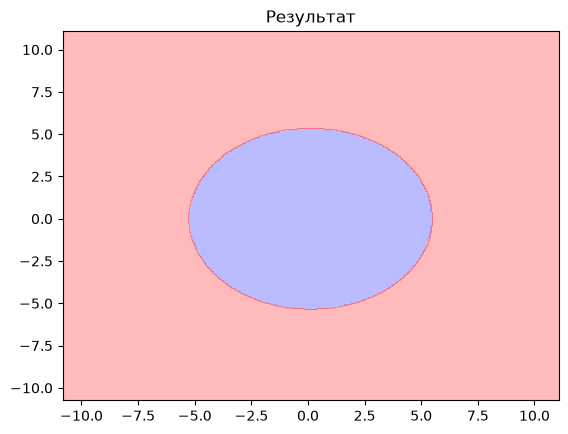

In [12]:
plt.contourf(xx, yy, Z, alpha=0.3, cmap='bwr')
plt.title('Результат')
plt.show()